# BO vs CMA-ES on a needle landscape

How do population size, restarts and acquisition choices change the chance that CMA-ES and GP-BO find a narrow, distant global basin at a fixed budget of N = 300 evaluations? Design: `docs/direction.md`. Predictions: `docs/predictions.md`.

**How to use this notebook.** It imports the engine in `code/` and shows the key steps as short cells. Nothing here runs in parallel. Long batches run through `run_experiments.py`.

- `FAST = True`: N = 100, 5 seeds. Runs are computed here (single process) and cached in `results/raw_fast/`.
- `FAST = False`: N = 300. Loads the saved runs in `results/raw/` and the summaries in `results/summary/`. Produce them first with `python run_experiments.py --full --exp exp0` then `--aggregate`.

All figures are saved to `docs/figures/` as `nb_*.png` (FAST mode adds a `_fast` suffix).

In [1]:
FAST = True   # True: N=100, 5 seeds, computed here.  False: N=300, load saved full results.

In [2]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "code"))
import torch; torch.set_num_threads(1)

import analysis as an
from benchmarks import get_landscape
from configs import CONFIGS, N_FAST, N_FULL, N_SEEDS_FAST, PRIMARY, SEEDS
from optimizers import run

N = N_FAST if FAST else N_FULL
RAW = ROOT / "results" / ("raw_fast" if FAST else "raw")
TAG = "_fast" if FAST else ""                       # figure-name suffix, so modes never overwrite each other
SEED, GRID_SEEDS = SEEDS[0], SEEDS[:4]          # seed 1000; grid seeds 1000-1003 (fixed rule)
ls = get_landscape(PRIMARY)
print(f"mode={'FAST' if FAST else 'FULL'}  N={N}  landscape={ls.name}  epsilon={ls.epsilon}")

mode=FAST  N=100  landscape=primary_far_w0.3  epsilon=0.05


## 1. The primary landscape

A broad decoy bowl centred at $c$ plus one narrow, deep Gaussian well at $x_g$:

$$f(x) = \frac{\lVert x - c\rVert^2}{s} \;-\; A\,\exp\!\left(-\frac{\lVert x - x_g\rVert^2}{2w^2}\right)$$

Here $c = 0$, $s = 10$, $A = 4$, $w = 0.3$, and the "far" well sits at $x_g = (3, 3)$, about 4.2 from the decoy centre. The domain is $[-5, 5]^2$. A run **succeeds** when its best value is within $\varepsilon = 0.05$ of the true minimum, which random sampling at N = 300 reaches in only 2.5% of pilot seeds (`docs/figures/epsilon_check.png`).

The 3D view shows the well is a thin spike next to a huge, smooth bowl. The contour map shows where each is.

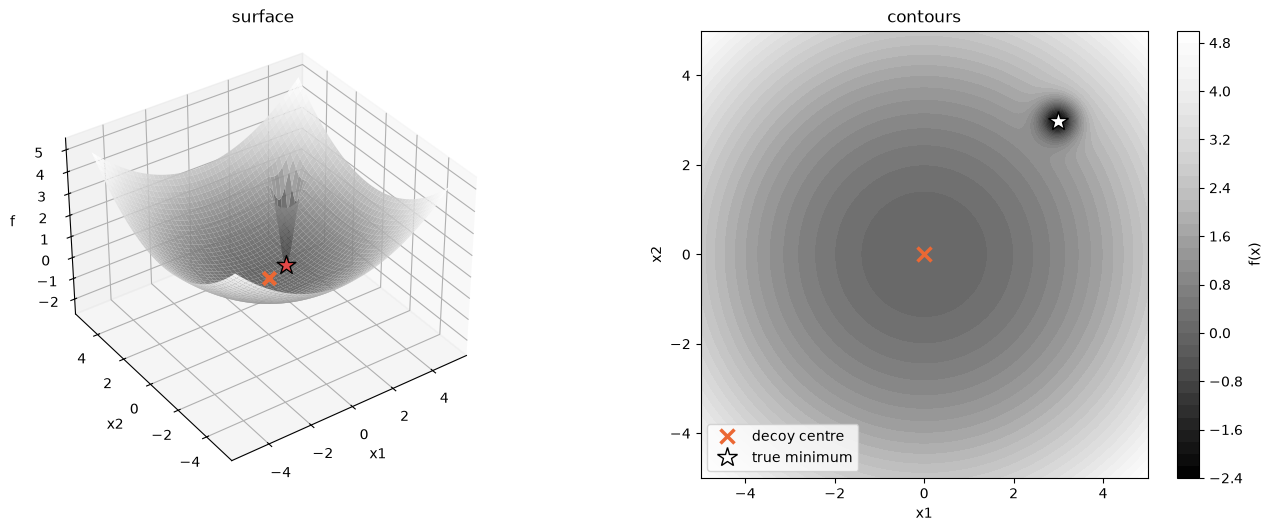

true minimum x* = [2.987 2.987], f* = -2.208;  decoy minimum f = -0.000


In [3]:
fig = plt.figure(figsize=(13, 5.2), layout="constrained")
ax = fig.add_subplot(1, 2, 1, projection="3d", computed_zorder=False); an.surface3d(ax, ls); ax.set_title("surface")
ax = fig.add_subplot(1, 2, 2); cs = an.mark_landscape(ax, ls)
fig.colorbar(cs, ax=ax, label="f(x)"); ax.legend(loc="lower left"); ax.set_title("contours")
an.save_fig(fig, f"nb_1_landscape{TAG}.png"); plt.show()
print(f"true minimum x* = {ls.x_star.round(3)}, f* = {ls.f_star:.3f};  decoy minimum f = {ls(ls.meta['c']):.3f}")

## 2. Default CMA-ES on one seed (1000)

CMA-ES starts at a random point, samples $\lambda = 6$ points per generation from $\mathcal N(m, \sigma^2 C)$ and moves toward the best ones. **Left:** samples coloured by generation (light = early, dark = late). The diamond is the start and the red ellipses are the 1-sigma search distribution at a few generations. **Right:** step size $\sigma$ per generation on a log axis. A steady collapse means the search is contracting onto whatever basin it is in.

In [4]:
log = run(ls, N, SEED, CONFIGS["cma_default"], "cma_default")      # engine, single process
cma, dist = pd.DataFrame(log.rows), log.meta["dist"]
gens = np.unique(np.geomspace(1, cma["gen"].max() + 1, 4).round().astype(int) - 1)   # a few generations, denser early

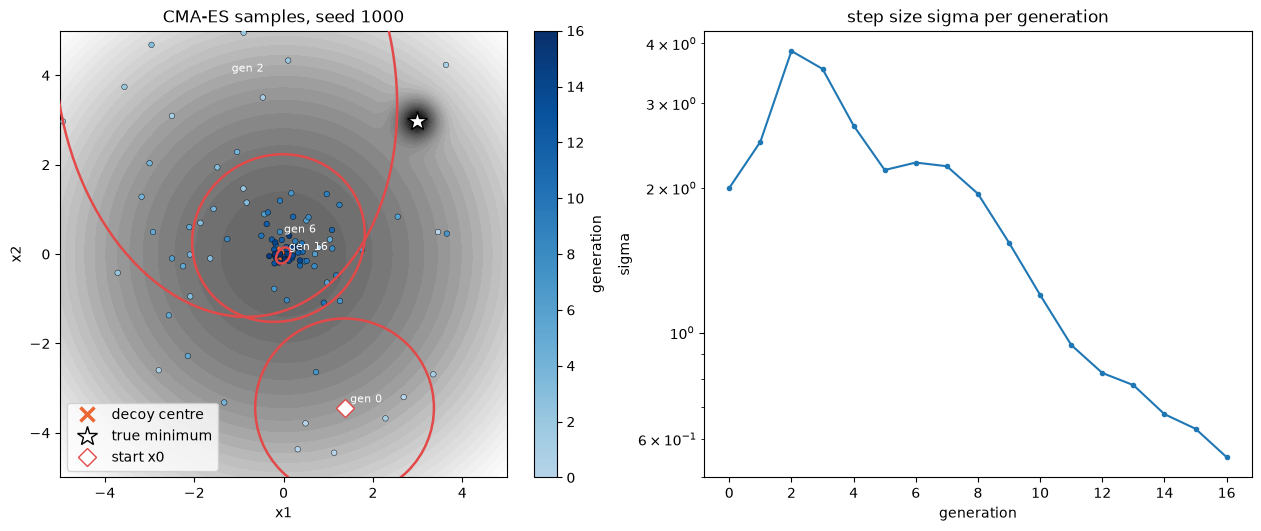

best regret = 2.209, final sigma = 0.5500, generations = 17


In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.2), layout="constrained")
sc = an.scatter_run(a1, ls, cma, by="gen"); an.draw_ellipses(a1, dist, gens)
fig.colorbar(sc, ax=a1, label="generation"); a1.legend(loc="lower left"); a1.set_title(f"CMA-ES samples, seed {SEED}")
an.plot_sigma_trace(a2, cma); a2.set_title("step size sigma per generation")
an.save_fig(fig, f"nb_2_cmaes_seed1000{TAG}.png"); plt.show()
print(f"best regret = {ls.regret(cma['f'].min()):.3f}, final sigma = {cma['sigma'].iloc[-1]:.4f}, generations = {cma['gen'].max() + 1}")

## 3. Default BO on the same seed (1000)

BO fits a Matern-5/2 GP to the evaluations so far and picks the next point by expected improvement (EI, $\xi = 0$). It starts from 10 space-filling points (white squares) and the later points are coloured by the order in which they were chosen. A BO run that explores would spread later points across the box. A BO run that over-smooths the well keeps re-sampling the bowl.

In [6]:
bo = an.load_or_run("bo_default", PRIMARY, SEED, N, RAW, allow_run=FAST)
n_init = CONFIGS["bo_default"]["n_init"]

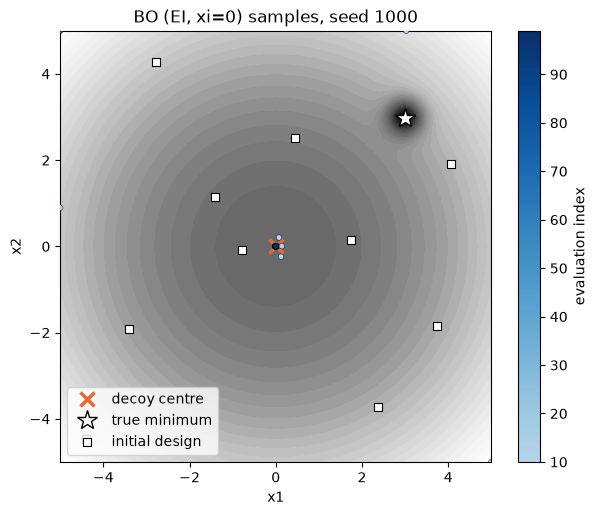

best regret = 2.208; final fitted lengthscales (domain units) = 20;20; well width w = 0.3


In [7]:
fig, ax = plt.subplots(figsize=(7, 5.6))
sc = an.scatter_run(ax, ls, bo, n_init=n_init)
fig.colorbar(sc, ax=ax, label="evaluation index"); ax.legend(loc="lower left"); ax.set_title(f"BO (EI, xi=0) samples, seed {SEED}")
an.save_fig(fig, f"nb_3_bo_seed1000{TAG}.png"); plt.show()
ell = bo["lengthscales"].dropna().iloc[-1]
print(f"best regret = {ls.regret(bo['f'].min()):.3f}; final fitted lengthscales (domain units) = {ell}; well width w = {ls.meta['w']}")

## 4. Four seeds each, side by side

The same view for seeds 1000-1003, with the seeds fixed by rule (the first four of the fixed list, not picked for how they look). **Top row:** CMA-ES. **Bottom row:** BO. Colour is evaluation order in both rows. The title gives each run's best regret.

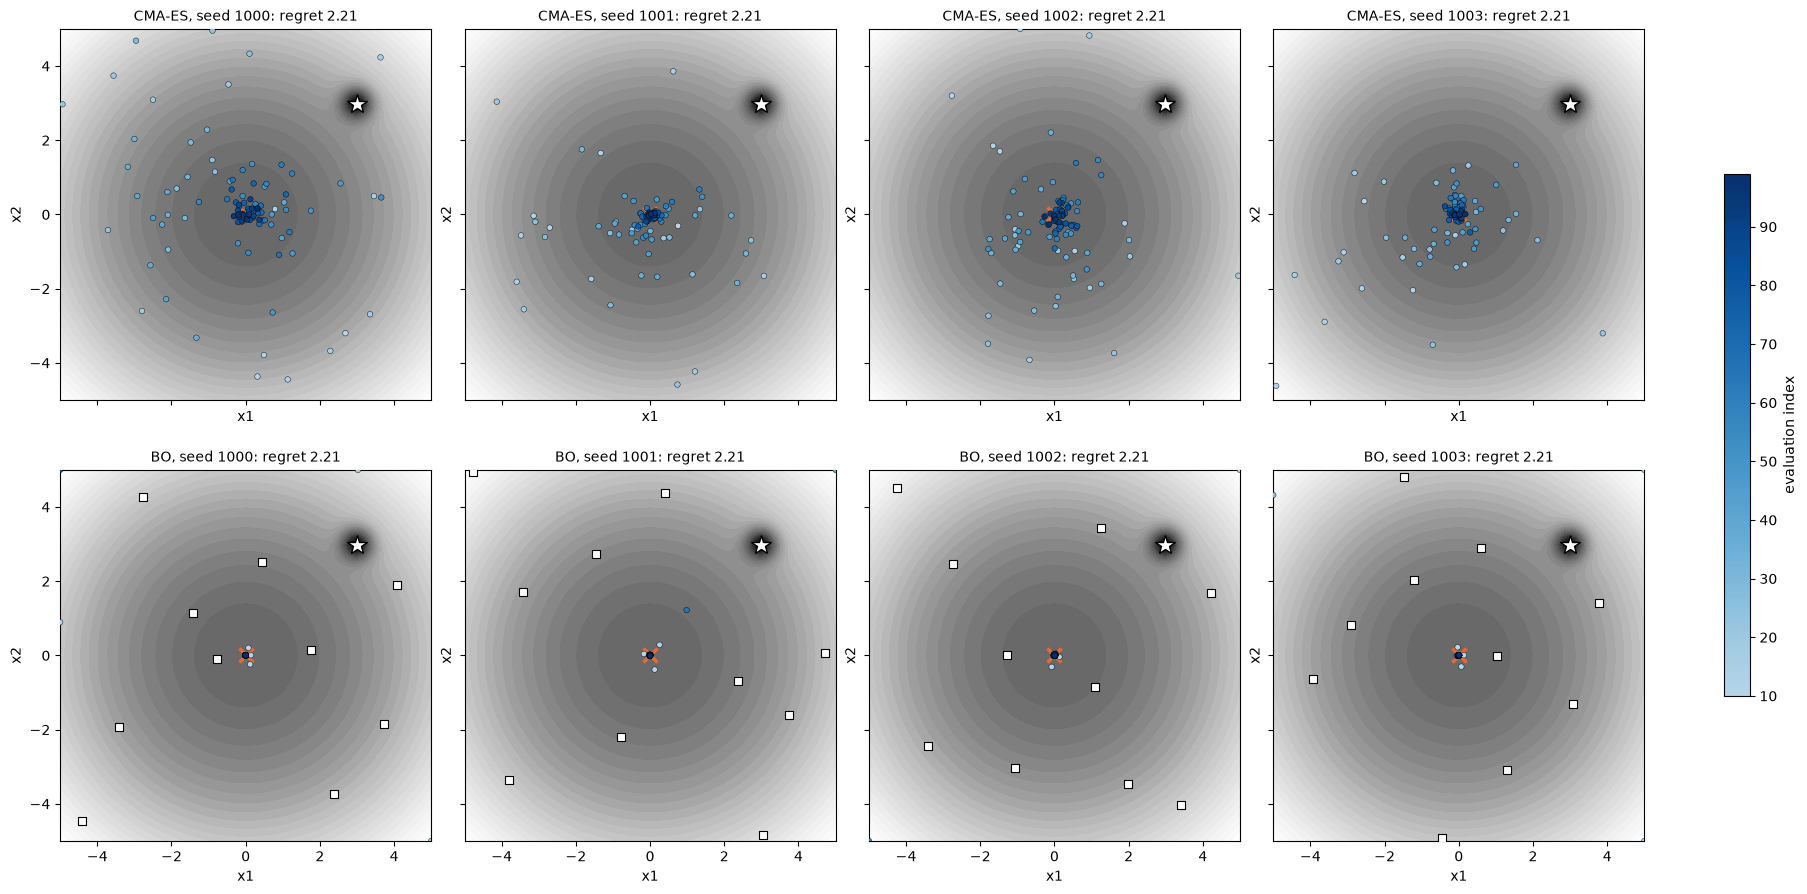

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9), sharex=True, sharey=True, layout="constrained")
for j, seed in enumerate(GRID_SEEDS):
    for i, cid in enumerate(["cma_default", "bo_default"]):
        run_df = an.load_or_run(cid, PRIMARY, seed, N, RAW, allow_run=FAST)
        sc = an.scatter_run(axes[i, j], ls, run_df, n_init=CONFIGS[cid]["n_init"] if cid.startswith("bo") else 0)
        axes[i, j].set_title(f"{'CMA-ES' if i == 0 else 'BO'}, seed {seed}: regret {ls.regret(run_df['f'].min()):.2f}", fontsize=10)
fig.colorbar(sc, ax=axes, shrink=0.6, label="evaluation index")
an.save_fig(fig, f"nb_4_grid_seeds1000_1003{TAG}.png"); plt.show()

## 5. Success rate and outcomes

For each method on the primary landscape: the success rate with a Wilson 95% interval, and a stacked bar of what happened to every run.

- **success**: best regret $\le \varepsilon$ (0.05).
- **stuck in decoy**: the best point found does not lead to the well (local descent from it ends in the decoy).
- **unfinished**: the best point is in the well's basin but not within $\varepsilon$ of the minimum, so the run found the basin but did not finish refining.

Read the intervals before the bars: with so few seeds they are wide, and a claim needs separated intervals. FAST mode loads the runs it just made. FULL mode reads `results/summary/runs.csv`.

In [9]:
BASE = ["cma_default", "bo_default"]
if FAST:
    for cid in BASE:
        for seed in SEEDS[:N_SEEDS_FAST]:
            an.load_or_run(cid, PRIMARY, seed, N, RAW)
    runs = an.summarise_runs(an.load_raw(RAW, PRIMARY))
else:
    runs = pd.read_csv(ROOT / "results" / "summary" / "runs.csv")
runs = runs[(runs["landscape"] == PRIMARY) & runs["config_id"].isin(BASE)]
tab = an.success_table(runs)
display(tab[tab["metric"] == "success"][["config_id", "k", "n", "rate", "ci_lo", "ci_hi", "median_regret"]].round(3))

,config_id,k,n,rate,ci_lo,ci_hi,median_regret
0,bo_default,0,5,0.0,0.0,0.434,2.208
1,cma_default,0,5,0.0,0.0,0.434,2.208


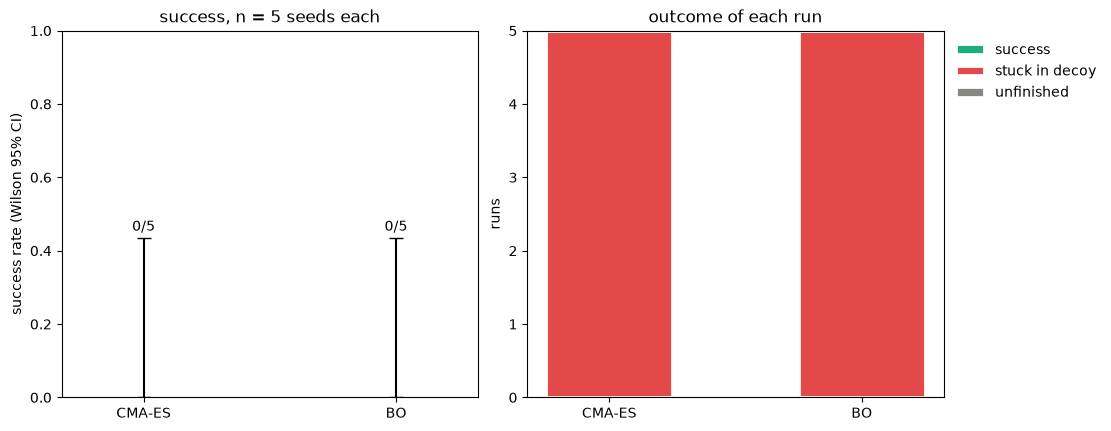

outcome,success,stuck in decoy,unfinished
config_id,,,
cma_default,0,5,0
bo_default,0,5,0


In [10]:
counts = an.outcome_counts(runs).loc[BASE]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
t = tab[tab["metric"] == "success"].set_index("config_id").loc[BASE]
cols = [an.BLUE, an.ORANGE]
a1.bar(["CMA-ES", "BO"], t["rate"], color=cols, width=0.5)
a1.errorbar([0, 1], t["rate"], yerr=[t["rate"] - t["ci_lo"], t["ci_hi"] - t["rate"]], fmt="none", ecolor="k", capsize=5)
for x, (r, hi, k, n) in enumerate(zip(t["rate"], t["ci_hi"], t["k"], t["n"])): a1.text(x, hi + 0.02, f"{int(k)}/{int(n)}", ha="center")
a1.set_ylim(0, 1); a1.set_ylabel("success rate (Wilson 95% CI)"); a1.set_title(f"success, n = {int(t['n'].iloc[0])} seeds each")
bottom = np.zeros(len(BASE))
for o in an.OUTCOMES:
    a2.bar(["CMA-ES", "BO"], counts[o], bottom=bottom, color=an.OUTCOME_COLOURS[o], label=o, width=0.5, edgecolor="white", linewidth=2)
    bottom += counts[o].to_numpy()
a2.set_ylabel("runs"); a2.set_title("outcome of each run"); a2.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
an.save_fig(fig, f"nb_5_success_outcomes{TAG}.png"); plt.show()
display(counts)

## 6. Experiments to fill in later

Each placeholder holds its pre-registered prediction, copied from `docs/predictions.md` (not to be edited). Run the batch with `run_experiments.py`, then add the figure and the four-line write-up (prediction, result with CI, explanation, caveat) here.

### Exp A: population size $\lambda$ (1x, 2x, 4x default: 6, 12, 24)

Run: `python run_experiments.py --full --exp expA`, then `--aggregate`.

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| H2 | Larger lambda raises success, with a sweet spot at fixed N | Success vs lambda rises, then plateaus or falls | Monotone decline, or no change |
| M1 | On the needle (primary) landscape, larger lambda helps only through extra early samples: the bowl slopes toward the decoy, so there is no global trend for selection averaging to follow | Any lambda gain is explained by the chance that a first-generation sample lands in the global basin (best point found in an early generation; gain tracks number of early samples) | Successful large-lambda runs find the well in later generations after the mean has moved toward it |

*Result, explanation, caveat: to fill in after the run.* Also report generations completed per lambda.

### Exp B: restarts (none, IPOP, BIPOP; total budget fixed at N)

Run: `python run_experiments.py --full --exp expB`, then `--aggregate`. Restart triggers are frozen at tolx = 3e-3, tolfun = 1e-5.

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| H3 | Restarts beat a larger lambda at equal total budget | Higher success at the same N | Equal or lower success |
| M2 | On the needle landscape, restarts act like random search: each restart succeeds roughly when its fresh start (x0, sigma0) lands near the well | Success rate of IPOP/BIPOP close to what independent restarts from uniform x0 predict; successful restart index is spread out rather than concentrated on large-lambda restarts | Success concentrated in large-lambda restarts beyond what the restart count explains |

**Must report:** restart firing rate per lambda (pilot: 100% at lambda 6, 84% at 12, 0% at 24). At lambda = 24 restarts never fire, so IPOP/BIPOP there equal no restarts.

*Result, explanation, caveat: to fill in after the run.*

### Exp C: BO exploration (EI with xi, LCB with beta, Thompson sampling, MAP-fit arm)

Run: `python run_experiments.py --full --exp expC`, then `--aggregate`.

| ID | Prediction | Supported by | Contradicted by |
| --- | --- | --- | --- |
| H4 | BO finds the narrow basin at low d only if it explores enough | Success rises with xi or beta | Insensitive to xi and beta |

Also report sample spread and the fitted lengthscale against the well width w, and the Cholesky jitter-fallback count.

*Result, explanation, caveat: to fill in after the run.*

### Exp E: basin width (far well w in {0.1, 0.3, 0.6, 1.0}; near well w in {0.1, 0.3})

Run: `python run_experiments.py --full --exp expE_baseline`, then `--aggregate`. Near-well cells at w = 0.6 and 1.0 are excluded because the basins merge (see `docs/pilot_log.md`). Random sampling is the reference line.

`docs/predictions.md` has **no prediction dedicated to Exp E**. The nearest are H1 (default CMA-ES gets stuck in a decoy basin) and H4 (BO finds the narrow basin only if it explores enough). Do not add one after the pilot. State plainly in the write-up that the width sweep is exploratory.

*Result, explanation, caveat: to fill in after the run.*